# Experiment 4: out-of-fold targeted training

This experiment improves the hard-example selection used in Experiment 3. Instead of identifying hard training examples from in-sample predictions, it generates out-of-fold probabilities: every training example is predicted by a model that was not trained on that example.

The out-of-fold margins are then used to define hard training examples. Validation and test hardness is calculated from the final baseline model. Each threshold compares the targeted model with the baseline on the same validation/test subset.

## Imports

In [1]:
import os
import pickle
import sys

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold

sys.path.append("..")
from utils.hard_samples_identify import add_is_hard
from utils.preprocessing import LABELS, clean_text, encode_labels

np.random.seed(42)


## Load and preprocess the data

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

vectorizer = TfidfVectorizer(
    preprocessor=clean_text,
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df.sentence)
X_val = vectorizer.transform(val_df.sentence)
X_test = vectorizer.transform(test_df.sentence)

print(X_train.shape, X_val.shape, X_test.shape)


(2901, 39035) (967, 39035) (968, 39035)


## Train the baseline and generate out-of-fold training probabilities

Each training example receives a probability prediction from a fold model that did not use that example for fitting. These out-of-fold probabilities are used only to identify hard training examples.

In [3]:
def train_model(X, y, sample_weight=None):
    model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
    model.fit(X, y, sample_weight=sample_weight)
    return model

def margins(probabilities):
    top_two = np.partition(probabilities, -2, axis=1)[:, -2:]
    return top_two.max(axis=1) - top_two.min(axis=1)

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = np.zeros((len(y_train), len(LABELS)))

for fold_train, fold_held_out in folds.split(X_train, y_train):
    fold_model = train_model(X_train[fold_train], y_train[fold_train])
    oof_probabilities[fold_held_out] = fold_model.predict_proba(X_train[fold_held_out])

baseline_model = train_model(X_train, y_train)
val_probabilities = baseline_model.predict_proba(X_val)
test_probabilities = baseline_model.predict_proba(X_test)

train_margins = margins(oof_probabilities)
val_margins = margins(val_probabilities)
test_margins = margins(test_probabilities)

print("Out-of-fold training margins calculated.")


Out-of-fold training margins calculated.


## Compare thresholds using out-of-fold hard examples

Each threshold is applied to the out-of-fold training margins, validation margins, and test margins. For every threshold, the targeted model and baseline are evaluated on the same validation hard subset. The random control weights the same number of training examples as the targeted model.

In [4]:
def score(model, X, y, is_hard):
    predictions = model.predict(X)
    return {
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "hard_accuracy": accuracy_score(y[is_hard], predictions[is_hard]),
        "hard_f1": f1_score(y[is_hard], predictions[is_hard], average="macro"),
        "easy_accuracy": accuracy_score(y[~is_hard], predictions[~is_hard]),
        "easy_f1": f1_score(y[~is_hard], predictions[~is_hard], average="macro"),
    }

models = {"baseline": baseline_model}
validation_rows = []
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    train_is_hard = train_margins <= threshold
    val_is_hard = val_margins <= threshold
    test_is_hard = test_margins <= threshold

    hard_weights = np.where(train_is_hard, 3.0, 1.0)
    hard_name = f"hard_threshold_{threshold}"
    models[hard_name] = train_model(X_train, y_train, hard_weights)

    random_indices = np.random.default_rng(42).choice(
        len(y_train), size=train_is_hard.sum(), replace=False
    )
    random_weights = np.ones(len(y_train))
    random_weights[random_indices] = 3.0
    random_name = f"random_control_{threshold}"
    models[random_name] = train_model(X_train, y_train, random_weights)

    baseline_scores = score(baseline_model, X_val, y_val, val_is_hard)
    for name in [hard_name, random_name]:
        validation_rows.append({
            "condition": name,
            "threshold": threshold,
            "train_hard_count": int(train_is_hard.sum()),
            "val_hard_count": int(val_is_hard.sum()),
            "test_hard_count": int(test_is_hard.sum()),
            "baseline_hard_f1": baseline_scores["hard_f1"],
            **score(models[name], X_val, y_val, val_is_hard),
        })

validation_results = pd.DataFrame(validation_rows)
validation_results["hard_f1_change"] = (
    validation_results["hard_f1"] - validation_results["baseline_hard_f1"]
)
validation_results.sort_values("hard_f1_change", ascending=False)


,condition,threshold,train_hard_count,val_hard_count,test_hard_count,baseline_hard_f1,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1,hard_f1_change
0,hard_threshold_0.2,0.2,478,153,133,0.440803,0.781799,0.719673,0.516340,0.464320,0.831695,0.780639,0.023518
7,random_control_0.5,0.5,1302,380,352,0.544523,0.777663,0.721556,0.597368,0.552987,0.894378,0.854301,0.008464
8,hard_threshold_0.6,0.6,1623,469,455,0.573820,0.780765,0.716324,0.641791,0.570750,0.911647,0.881466,-0.003070
4,hard_threshold_0.4,0.4,989,300,282,0.502705,0.777663,0.714144,0.550000,0.495689,0.880060,0.835955,-0.007017
6,hard_threshold_0.5,0.5,1302,380,352,0.544523,0.778697,0.713291,0.600000,0.536016,0.894378,0.854301,-0.008507
5,random_control_0.4,0.4,989,300,282,0.502705,0.771458,0.713663,0.530000,0.493774,0.880060,0.835955,-0.008931
9,random_control_0.6,0.6,1623,469,455,0.573820,0.769390,0.709898,0.618337,0.560887,0.911647,0.881466,-0.012933
2,hard_threshold_0.3,0.3,724,230,206,0.479569,0.774560,0.712259,0.513043,0.461517,0.856174,0.808132,-0.018051
3,random_control_0.3,0.3,724,230,206,0.479569,0.770424,0.709711,0.495652,0.453966,0.856174,0.808132,-0.025603
1,random_control_0.2,0.2,478,153,133,0.440803,0.770424,0.710574,0.437908,0.407443,0.832924,0.781945,-0.033360


## Select the best condition

The best hard-targeted condition is selected using its improvement over the baseline on the same validation hard subset. If no hard-targeted condition improves over the baseline, the baseline remains selected.

In [5]:
best_targeted = validation_results[
    validation_results.condition.str.startswith("hard_threshold_")
].sort_values("hard_f1_change", ascending=False).iloc[0]

if best_targeted.hard_f1_change > 0:
    best_condition = best_targeted.condition
else:
    best_condition = "baseline"

print("Selected condition:", best_condition)


Selected condition: hard_threshold_0.2


## Final test evaluation

The selected model is evaluated on the test hard/easy split for its threshold. TP and FN are reported for each class within the hard subset.


baseline
              precision    recall  f1-score   support

    negative       0.75      0.63      0.68       121
     neutral       0.82      0.87      0.84       575
    positive       0.71      0.66      0.68       272

    accuracy                           0.78       968
   macro avg       0.76      0.72      0.74       968
weighted avg       0.78      0.78      0.78       968

Hard negative: TP=6, FN=14
Hard neutral: TP=33, FN=29
Hard positive: TP=28, FN=23

hard_threshold_0.2
              precision    recall  f1-score   support

    negative       0.77      0.62      0.69       121
     neutral       0.81      0.88      0.84       575
    positive       0.71      0.64      0.67       272

    accuracy                           0.78       968
   macro avg       0.76      0.71      0.73       968
weighted avg       0.78      0.78      0.77       968

Hard negative: TP=5, FN=15
Hard neutral: TP=40, FN=22
Hard positive: TP=21, FN=30


,condition,threshold,train_hard_count,test_hard_count,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1
0,baseline,0.2,478,133,0.779959,0.736191,0.503759,0.467763,0.823952,0.782631
1,hard_threshold_0.2,0.2,478,133,0.778926,0.733317,0.496241,0.447172,0.823952,0.782631


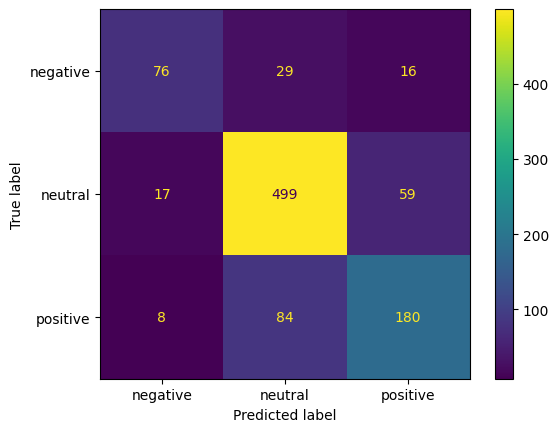

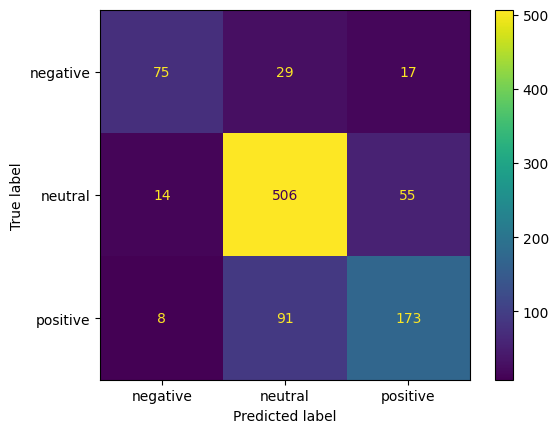

In [6]:
selected_threshold = 0.2 if best_condition == "baseline" else float(
    best_condition.rsplit("_", 1)[-1]
)
test_is_hard = test_margins <= selected_threshold

test_rows = []
for name in ["baseline"] + ([] if best_condition == "baseline" else [best_condition]):
    model = models[name]
    predictions = model.predict(X_test)
    test_rows.append({
        "condition": name,
        "threshold": selected_threshold,
        "train_hard_count": int((train_margins <= selected_threshold).sum()),
        "test_hard_count": int(test_is_hard.sum()),
        **score(model, X_test, y_test, test_is_hard),
    })

    hard_true = y_test[test_is_hard]
    hard_pred = predictions[test_is_hard]
    print("\n" + name)
    print(classification_report(y_test, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=LABELS)

    for class_id, label in enumerate(LABELS):
        tp = ((hard_true == class_id) & (hard_pred == class_id)).sum()
        fn = ((hard_true == class_id) & (hard_pred != class_id)).sum()
        print(f"Hard {label}: TP={tp}, FN={fn}")

test_results = pd.DataFrame(test_rows)
test_results


## Save results

In [ ]:
os.makedirs("../models", exist_ok=True)

validation_results.to_csv("../results/experiment_4_validation_oof.csv", index=False)
test_results.to_csv("../results/experiment_4_test_oof.csv", index=False)

train_df = add_is_hard(train_df, oof_probabilities, 0.2)
val_df = add_is_hard(val_df, val_probabilities, 0.2)
test_df = add_is_hard(test_df, test_probabilities, 0.2)
train_df.to_csv("../results/experiment_4_train_with_hard.csv", index=False)
val_df.to_csv("../results/experiment_4_val_with_hard.csv", index=False)
test_df.to_csv("../results/experiment_4_test_with_hard.csv", index=False)

with open("../models/experiment_4_tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)
with open("../models/experiment_4_baseline_logreg.pkl", "wb") as f:
    pickle.dump(baseline_model, f)
with open("../models/experiment_4_selected_logreg.pkl", "wb") as f:
    pickle.dump(models[best_condition], f)
